# Part 2: Exploratory Data Analysis
**Predictive Championship Modeling by Rachel Chen, Darryl Fu, and Zubair Syed**

This file contains our answers to Project Part 2, and our Exploratory Data Analysis of professional Track & Field data in the years 2024, 2025, and 2026.

## Research Questions
1. How accurately can we predict an athlete’s future championship standing based on their results in the past and current seasons?
2. How can we refine this model, encompassing more abstract factors like competition tactics, weighting different results by how long ago they were, and by quantifying other traits of competition?
3. How can we comprehensively turn all our data into a user-friendly app, where users can compare athletes head-to-head and make predictions?

## Motivation
Predicting, analyzing, and betting on sports stats dates back to ancient athletics and horse racing, and is one of the key points that make football, soccer, and basketball the most profitable sports in the industry. Why can’t track and field have the same success? Can we get fans to interact more with track and field, and draw new fans to the sport? Athlete stats are perhaps most explicit in track and field. How can we use math, matrices, and data analysis to predict future winners? Since there is no T&F World Championship until Summer 2027, what would the 2026 outcomes look like, hypothetically?

## Dataset
We will be using official track & field results from `worldathletics.org` as our dataset. World Athletics is an international federation that governs events such as track & field and is a recognized source by the International Olympic Committee (IOC). Our data will require cleaning, as we will use records from individual athletes in our project. We will code an algorithm to scrape the data from World Athletics and use it to make our own machine learning model that predicts the performance of athletes.


## Method
* We will scrape data from World Athletics (worldathletics.org), choosing the 40 Olympic track & field events (20 women’s events and 20 men’s events). For each of the 40 Olympic events, we will obtain the Top List, consisting of the top 100 performances in each event over the current year.
* Then, for each athlete that appears in the Top Lists, we will dig into their profile. We will scrape all of the athlete’s 2025 performances to get a full view of their progression and trend over the season.
* The main pieces of data that our prediction model will take into account are the times/marks achieved in the current season, the times/marks achieved in the past season, and the level of tactics that the athlete has (most relevant to distance runners).
* Next:
    We will use the current season data to create a trendline using linear regression, and use this to analyze whether the athlete is improving as the season goes on, or is burning out or stagnating. 
    We will use the past season data to create a trendline as well, but also to see if an athlete is more likely to perform at their best in a championship race rather than a regular season race. This data will also be used to influence the tactical score of an athlete.
    We will weigh the current-season trend highest, and the past-season data and tactics less. However, we are considering adding an option for users to adjust the level of weight that tactics get, and see if the results change with this. 
    We will use 2024, 2025, and 2026 data to create our machine learning model. We will first use 2024 and 2025 data to write the weighted forward-pass prediction algorithm, excluding final results, and check it against the true results.
    Then, we will use 2025 and 2026 to predict the results of this year’s hypothetical World Championships (it is an off year, so there is no World Championship this year. However, that makes it all the more fun to predict or guess!)
* Lastly, we will implement our prediction model into our app, along with general information on T&F athletes and aesthetic design.


## EDA Results
We have 120 total datasets representing top lists. That is, we are considering 40 events (20 men’s events, 20 women’s events) over the 2024, 2025, and 2026 track seasons. 

For each of the 20 Olympic events in each season, we are considering the top 100 performers. For each of the top 100 performers, we have dug into their World Athletics profile and scraped all their season results into a csv, labeled with their World Athletics athlete ID number. In total, the 120 datasets containing 100 athlete names each have returned to us 5,861 athlete’s season profiles.

We have thus created two types of datasets: the `event_file` and the `athlete_file`. The `event_file` datasets contain 100 elements, and the `athlete_file` datasets contain varying numbers of elements, depending on how many times the athlete competed at a World Athletics verified competition. The number of performances throughout a season vary from 5 to 15+ performances. 

Our dataset does not have any missing data, however, there are instances of DNS, DNF, and NH/NM marks in track and field events (Did Not Start, Did Not Finish, No Height, No Mark). Since these results cannot be fairly interpreted or graphed in any way, our team has resolved to simply drop these results by filtering them out of the DataFrames. 

Since it seems unrealistic to conduct EDA for all 120 of our Top List datasets, we will be plotting and finding summary statistics for various events, years, and athletes. We have covered sprint events, long-distance events, throwing events, and jumping events in our EDA, with each type of competition having a couple of its own plots and summary statistics. 

In [2]:
# Import statements
import pandas as pd 
import seaborn as sns
import numpy as np
import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

First, we have a few helper methods. 

`to_float` and `add_year_df` are key helper methods that are used in just about every plotting function. Further details can be found in their docstrings.

In [3]:
def to_float(mark: str) -> float:
    """ 
    Converts str representation of mark into float for readability.
    Ignores DQs and DNs. If mark is in seconds, additional process
    is required to convert str representation of time to float.
    """
    mark = str(mark) # cast to string so we can check if ':' is in it
    mark.strip('h') # that appears in some apparently
    if 'DQ' in mark or 'DN' in mark:
        # we just skip over it
        pass
    
    elif ':' in mark:
        units = mark.split(":")
        if len(units) == 3:
            # then it is a marathon results in order hh:mm:ss
            return int(units[0]) * 3600 + int(units[1]) * 60 + int(units[2]) 
        else:
            # it is a mm:ss.ms results
            return int(units[0]) * 60 + float(units[1])
        
    else:
        return float(mark)    

In [4]:
def add_year_df(athlete_id: int) -> pd.DataFrame:
    """
    Will add a 'year' column to given athlete's csv data. Helps
    easily access year for any meet an athlete did.
    """
    # Read csv
    athlete_data = pd.read_csv("athlete_files/" + str(athlete_id) + '.csv')
    
    # Make list consisting of the last 4 characters, e.g. the year from the date
    dates = athlete_data['date']
    year = [int(date[-4:]) for date in dates]

    # Create new column
    athlete_data['year'] = year
    return athlete_data    

In [5]:
def running(event: str):
    """
    Checks if the event is a running event based on whether the event string
    contains the key words 'Metres', 'Marathon', or 'Mile'
    """
    return any(word in event for word in ['Metres', 'Marathon', 'Mile'])

We have created a tentative color palette for our project that we hope to take further when creating the Fan UI. We will be referencing colors from this palette throughout all the plots.

In [6]:
# Palette for all our following visualizations
my_palette = ['#FFC107', '#FF3830', '#00BFA5', '#3D8BFF', '#B388FF', '#F2F4F7']

## 7-Number Summary
We begin finding summary statistics and creating plots for our data now.
* `summary7n` finds the 7-number summary (mean, standard deviation, minimum, first quartile, median, third quartile, maximum) for an individual athlete's performance in a given event and year.
* `event_7n_summary` finds the 7-number summary across all performances in an event in a given year.
* `get_summary`, `print_7n_summary_individual`, `print_7n_summary_event` are all helper methods that find and display the results. More details can be found in docstrings. 

In [7]:
def summary7n(athlete_id: int, event: str, year: int) -> list[int]:
    """
    Reads in athlete data and returns 7 number summary of athlete marks and results score.
    Seven number summary includes: mean, standard deviation, minimum, first quartile,
    median, third quartile, and maximum.
    """
    # Read csv
    athlete_data = pd.read_csv("athlete_files/" + str(athlete_id) + '.csv')
    
    # Add year column
    athlete_data = add_year_df(athlete_id)
    
    # Filter
    athlete_data = athlete_data[(athlete_data['discipline'] == event) & (athlete_data['year'] == year)]
    
    # Create a Series from mark column, converted to type float
    marks = athlete_data['mark'].apply(to_float)

    # 7 num summary for mark:
    marks_summary = get_summary(marks)

    # Create a Series from resultScore column
    # 7 num sum for resultScore:
    result_scores = athlete_data['resultScore']
    rs_summary = get_summary(result_scores)
    return (marks_summary, rs_summary)

# Helper Method
def get_summary(data: pd.Series) -> list[float]:
    """
    Returns seven number summary of a list or Pandas Series.
    """
    summary = [data.mean(), data.std(), data.min(), data.quantile(0.25), data.median(), data.quantile(0.75), data.max()]
    return [round(float(val), 2) for val in summary]

def print_7n_summary_individual(details: list[str], marks_summary: list[float], scores_summary: list[float]) -> None:
    """
    Prints athlete marks and results score from seven number summary
    in a readable fashion.
    """
    print(details[0], details[1], details[2] + ' Results: ')
    print("[mean, standard deviation, minimum, first quartile, median, third quartile, maximum]")
    print("Marks:", marks_summary)
    print("Scores", scores_summary)

### Athlete 7-Number-Summary
Prints the 7-number-summary for Grant Fisher's performances across the 5000 Metres in the 2025 season.

In [8]:
athlete_id = 14591210
name = pd.read_csv('athlete_files/' + str(athlete_id) + '.csv')['name'][0]
event = "5000 Metres"
year = 2025

details = [name, year, event]
marks_summary, scores_summary = summary7n(athlete_id, event, year)
print_7n_summary_individual(details, marks_summary, scores_summary)

Grant FISHER 2025 5000 Metres Results: 
[mean, standard deviation, minimum, first quartile, median, third quartile, maximum]
Marks: [816.22, 34.99, 780.79, 793.07, 813.54, 821.45, 879.14]
Scores [1083.17, 118.63, 873.0, 1062.25, 1089.5, 1162.5, 1207.0]


### Athlete 7-Number-Summary
Prints the 7-number-summary for Danil Lysenko's performances across the High Jump in the 2025 season.

In [9]:
athlete_id = 14576019
name = pd.read_csv('athlete_files/' + str(athlete_id) + '.csv')['name'][0]
event = "High Jump"
year = 2025

details = [name, year, event]
marks_summary, scores_summary = summary7n(athlete_id, event, year)
print_7n_summary_individual(details, marks_summary, scores_summary)

Danil LYSENKO 2025 High Jump Results: 
[mean, standard deviation, minimum, first quartile, median, third quartile, maximum]
Marks: [2.28, 0.05, 2.15, 2.27, 2.29, 2.3, 2.35]
Scores [1073.21, 311.5, 0.0, 1139.25, 1156.5, 1179.0, 1224.0]


### Event 7-Number-Summary
Finds and prints the 7-number-summary of performances across an event in a given year.

In [10]:
def event_7n_summary(event_name: str) -> tuple[list[float], list[float]]:
    """
    Reads in event data and returns 7 number summary of event marks and results score.
    Seven number summary includes: mean, standard deviation, minimum, first quartile,
    median, third quartile, and maximum.
    """
    # Read csv
    event_data = pd.read_csv('event_files/' + event_name + '.csv')
        
    # Create a Series from mark column, converted to type float
    marks = event_data['Mark'].apply(to_float)

    # Create a Series from mark column
    # 7 num summary for mark:
    marks_summary = get_summary(marks)

    # Create a Series from resultScore column
    # 7 num sum for resultScore:
    result_scores = event_data['Results Score']
    rs_summary = get_summary(result_scores)
    return (marks_summary, rs_summary)

def print_7n_summary_event(event: str, marks_summary: list[float], scores_summary: list[float]) -> None:
    """
    Prints event marks and results score from seven number summary
    in a readable fashion.
    """
    print(event, "Results:")
    print("[mean, standard deviation, minimum, first quartile, median, third quartile, maximum]")
    print("Marks:", marks_summary)
    print("Scores", scores_summary)

### Event 7-Number-Summary
Prints the 7-number-summary for the top 100 results in the Women's 100 Metres Hurdles across the 2026 season. 

In [11]:
event_name = "2026 Women's 100 Metres Hurdles"

marks_summary, scores_summary = event_7n_summary(event_name)
print_7n_summary_event(event_name, marks_summary, scores_summary)

2026 Women's 100 Metres Hurdles Results:
[mean, standard deviation, minimum, first quartile, median, third quartile, maximum]
Marks: [13.0, 0.17, 12.4, 12.92, 13.01, 13.13, 13.25]
Scores [1151.54, 22.62, 1116.0, 1134.0, 1150.5, 1162.0, 1232.0]


## Boxplots
We move into boxplots that display the summary statistics for each event, and for each athlete. This allows us to see the 5-number summary more effectively, and lets us easily compare the typical performance and variation in performances of athletes. We can see the Results Score of the athlete side-by-side as well.

`event_boxplot` lets us compare results across a given event

`athlete_boxplot` lets us see the summary statistics across an individual athlete.

In [12]:
def event_boxplot(event: str) -> None:
    """
    Plots boxplot visualization of given event, given the full name of an existing csv.
    """
    event_df = pd.read_csv("event_files/" + event + ".csv")
    
    # Plot
    fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(15, 7))

    sns.boxplot(data=event_df, y='Mark', ax=ax1, color=my_palette[1])
    ax1.set_title(event + " Yearly Mark Distribution", fontsize=18)
    ax1.set_ylabel("Mark (m)", fontsize=16)
    ax1.yaxis.set_major_locator(MaxNLocator(nbins=6))  # ~6 ticks max

    if running(event):
        # then it is a running event
        # and we reverse x axis since lower time is good result score
        # ax1.invert_yaxis()
        ax1.set_ylabel("Mark (s)", fontsize=16)

    sns.boxplot(data=event_df, y='Results Score', ax=ax2, color=my_palette[2])
    ax2.set_title(event + " Yearly Result Score Distribution", fontsize=18)
    ax2.set_ylabel("Results Score", fontsize=16)
    plt.tight_layout()
    plt.show()

In [13]:
def athlete_boxplot(athlete_id: int, event: str) -> None:
    """
    Plots boxplot visualization of given athlete, given the event that we would like to
    plot and the athlete's ID number
    """

    athlete_df = pd.read_csv("athlete_files/" + str(athlete_id) + ".csv")
    name = athlete_df['name'][0]
    athlete_df = athlete_df[athlete_df['discipline'] == event]
    
    # Plot
    fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(15, 7))

    sns.boxplot(data=athlete_df, y='mark', ax=ax1, color=my_palette[1])
    ax1.set_title(name + " Yearly Mark Distribution", fontsize=18)
    ax1.set_ylabel("Mark (m)", fontsize=16)
    ax1.yaxis.set_major_locator(MaxNLocator(nbins=6))  # limits amount of ticks on y axis

    if running(event):
        # then it is a running event
        # and we reverse x axis since lower time is good result score
        # ax1.invert_yaxis()
        ax1.set_ylabel("Mark (in time)", fontsize=16)

    sns.boxplot(data=athlete_df, y='resultScore', ax=ax2, color=my_palette[2])
    ax2.set_title(name + " Yearly Result Score Distribution", fontsize=18)
    ax2.set_ylabel("Results Score", fontsize=16)
    plt.tight_layout()
    plt.show()

### 2024 Men's Marathon: Boxplot and Distribution
Shows the distribution of performances and results scores across the 2024 Men's Marathon.

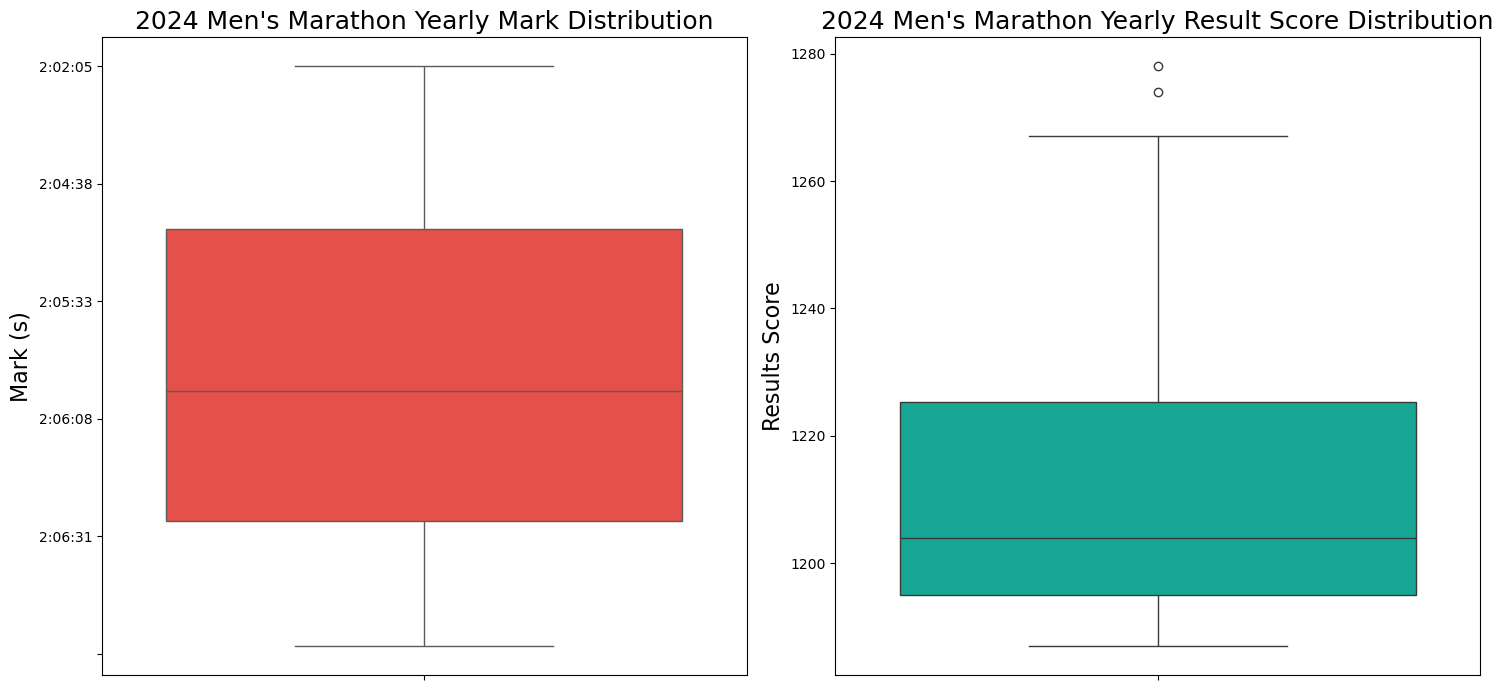

In [14]:
event_boxplot("2024 Men's Marathon")

### 2024 Women's Discus Throw: Boxplot and Distribution
Shows the distribution of performances and results scores across the 2024 Women's Discus Throw.

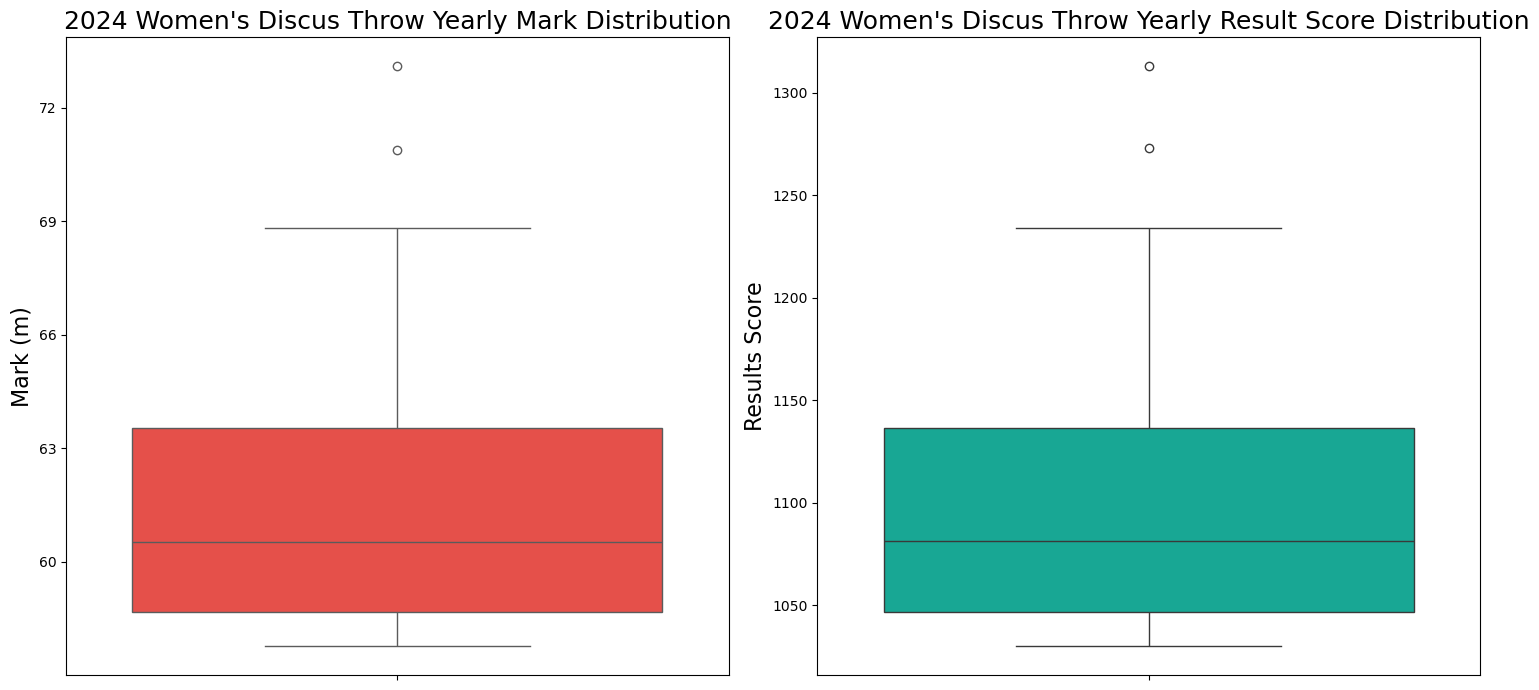

In [15]:
event_boxplot("2024 Women's Discus Throw")

## Box Plot: Mark Distribution
Shows the spread of marks across the season for an individual's specific event. It is useful for understanding how consistent or fickle an athlete's performance can be.

### Jane Hedengren: Boxplot and Distribution for the 5000 Metres
Shows Jane Hedengren's distribution of performances and results scores across the 5000 Metres for all three years, 2024, 2025, and 2026.

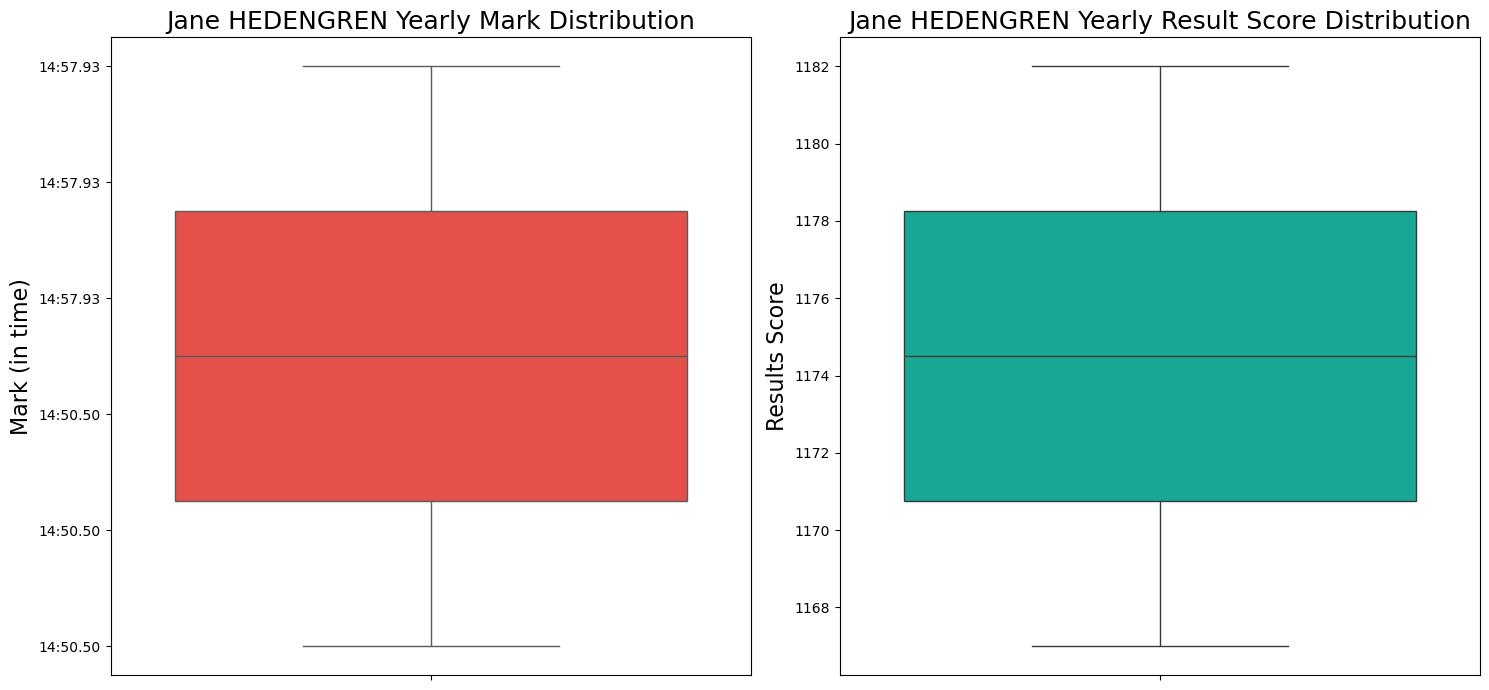

In [16]:
athlete_boxplot(15090151, '5000 Metres')

### Blessed Owusu Jr.: Boxplot and Distribution for the 400 Metres
Shows Blessed Owusu Jr.'s distribution of performances and results scores across the 400 Metres for all three years, 2024, 2025, and 2026.

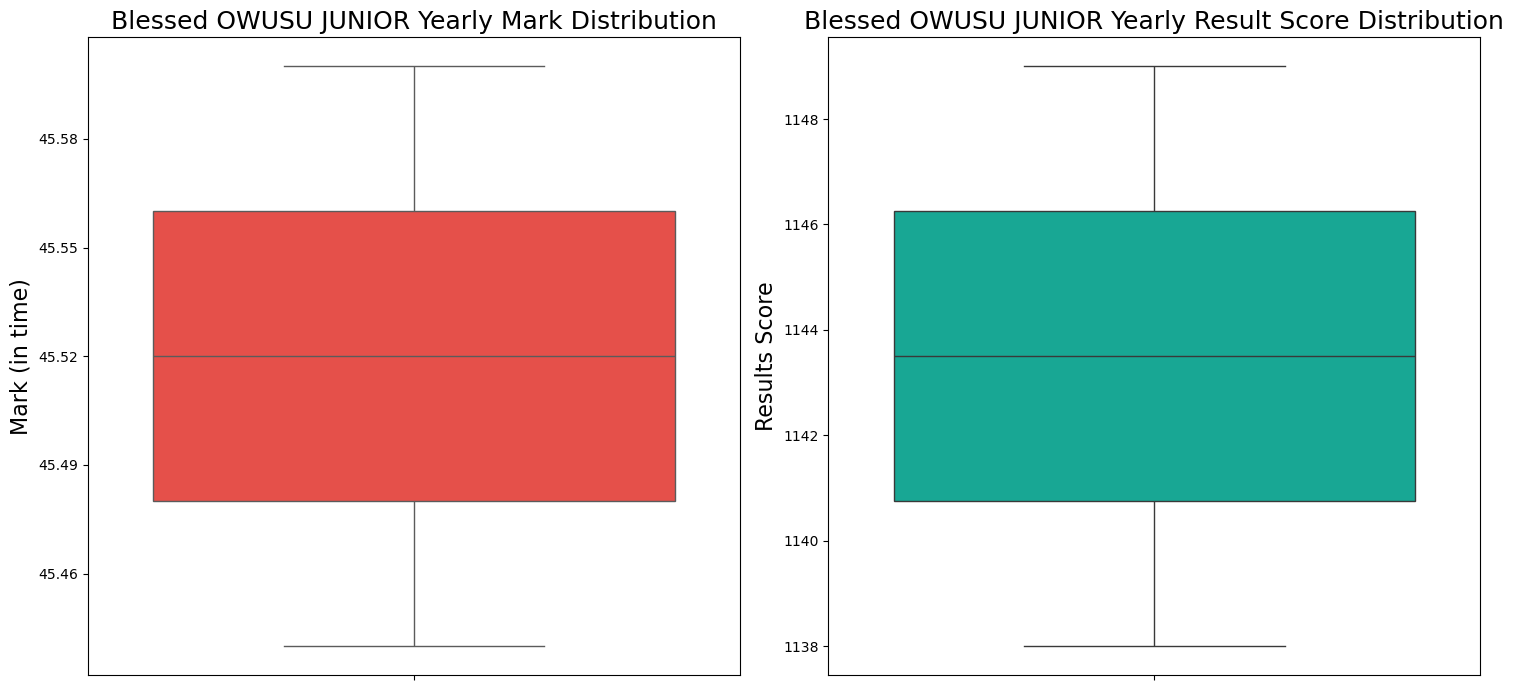

In [17]:
athlete_boxplot(15302671, '400 Metres')

## Regression Plots
The following plots create a regression line for a certain athlete in a certain year and event. Captures season performance direction for an individual. The regression line allows us to see if athletes peak early or progressively improve through the season. This is useful for future prediction models.

In [18]:
def plot_reg(athlete_id, year, event):
    """
    Uses a DataFrame-based approach to plot athlete trajectory
    using linear regression. Requires year and event specification
    to pinpoint which data to analyze.
    """
    # Filter date
    athlete_data = add_year_df(athlete_id)
    athlete_data = athlete_data[athlete_data['year'] == year]
    athlete_data['date'] = pd.to_datetime(athlete_data['date'], format='%d %b %Y')

    # Filter events
    athlete_data = athlete_data[athlete_data['discipline'] == event] 
    athlete_data['mark'] = [to_float(mark) for mark in athlete_data['mark']]
    
    # Change date to num
    athlete_data['date_num'] = mdates.date2num(athlete_data['date'])
    sns.regplot(data=athlete_data, x='date_num', y='mark')
    ax = plt.gca()
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))

    ax.set_title(event + " Season Trajectory")
    ax.set_xlabel("Date")
    ax.set_ylabel("Mark (s)")
    plt.xticks(rotation=45)

### Season Trajectory: Grant Fisher (5000 Metres)
Linear regression shows the race results over the 2025 season for athlete 14591210. Each point is a single race; the line shows the overall trend.

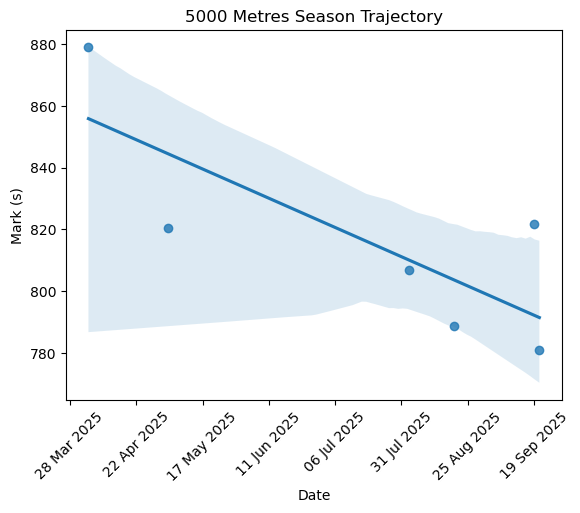

In [19]:
plot_reg(14591210, 2025, '5000 Metres')

### Top 8 Women's 5000 Metres — Season Trajectories (2025)
We can also plot several regression lines - one for each of the top 8 athletes in an event and year - and view their trends together. 
Contribution: This how each athlete's performances trended across the 2025 season. Each point is a single race, and the line shows the overall trend. We put the individual trend against the top 15. If all fifteen line slopes have the same direction, it suggests inaccuracies in our data. 

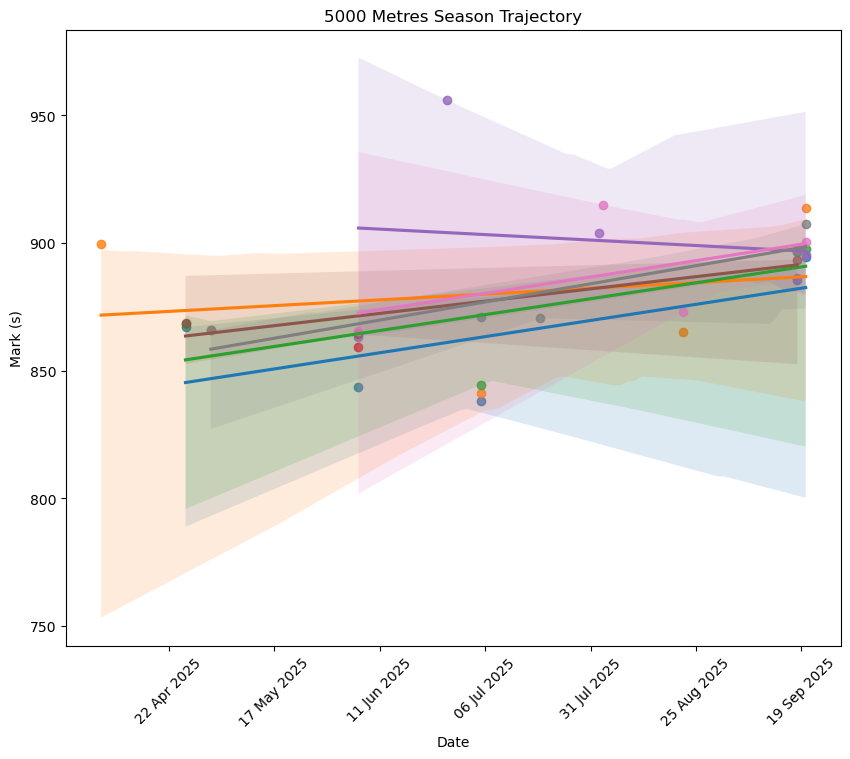

In [20]:
womens5kdata = pd.read_csv("event_files/2025 Women's 5000 Metres.csv")
womens5kdata = womens5kdata[:8]
fig, ax = plt.subplots(figsize=(10, 8))

for runner_id in womens5kdata['athlete_id']:
    plot_reg(runner_id, 2025, '5000 Metres')

### Top 9 Men's 100 Metres — Season Trajectories (2025)
Overlaid regression lines for the top 8 ranked 100m athletes in 2025.Shows how each athlete's performances trended across the season. Each point is a single race, and the line shows the overall trend.

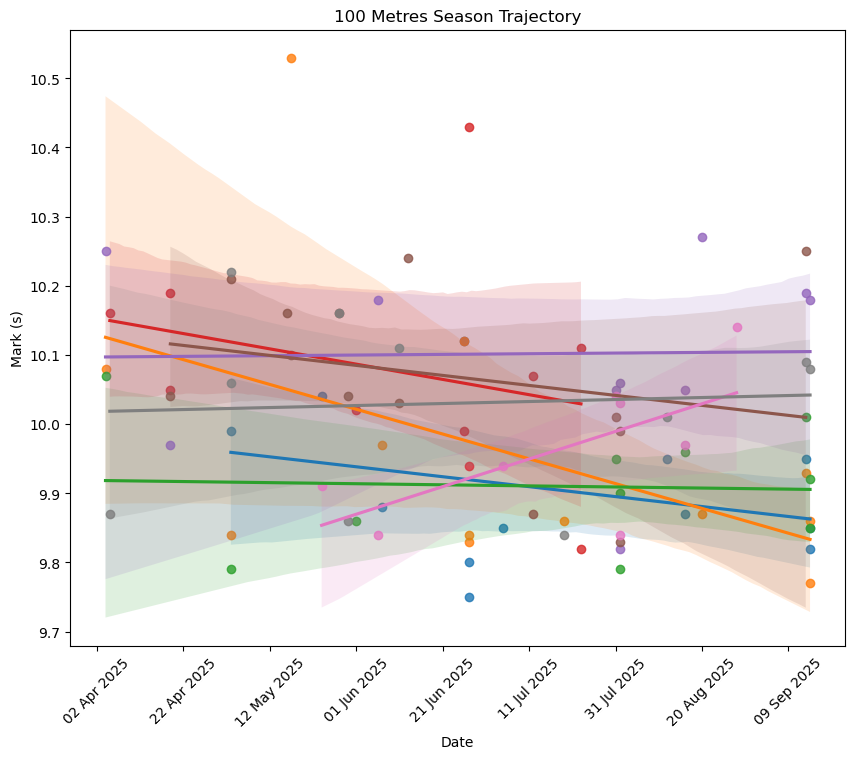

In [21]:
mens100data = pd.read_csv("event_files/2025 Men's 100 Metres.csv")
mens100data = mens100data[:8]

fig, ax = plt.subplots(figsize=(10, 8))

for runner_id in mens100data['athlete_id']:
    plot_reg(runner_id, 2025, '100 Metres')

## Mark vs. Score
World Athletics assigns 'Results Scores' to each performance, based on how they stack up against others, and based on time. We compare the result score distribution with the mark distribution. If the shapes diverge, it suggests that the scoring function is non-linear. (More details can be found at https://worldathletics.org/world-ranking-rules/basics?).

In [22]:
def plot_mark_v_score(event: str) -> None:
    """
    Plots given event's mark and results score distribution with histogram.
    """
    df = pd.read_csv("event_files/" + event + ".csv")
    df['Mark'] = df['Mark'].apply(to_float)
    fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(15,7))
    
    # Set background color 
    ax1.set_facecolor(my_palette[2])
    ax2.set_facecolor(my_palette[2])
    
    sns.histplot(data=df, x='Mark', bins=8, ax=ax1, color = my_palette[1], edgecolor='white', linewidth=1.5)
    ax1.set_title(event + " Mark Distribution", fontsize=15)
    ax1.set_xlabel("Mark (m)", fontsize = 16)
    ax1.set_ylabel("Frequency", fontsize = 16)
    if running(event):
        # then it is a running event
        # and we reverse x axis since lower time is good result score
        ax1.set_xlim(df['Mark'].min(), df['Mark'].max())
        ax1.invert_xaxis()
        ax1.set_xlabel("Mark (s)", fontsize=16)
    
    sns.histplot(data=df, x='Results Score', bins=8, ax=ax2, color = my_palette[1], edgecolor='white', linewidth=1.5)
    ax2.set_title(event + " Results Score Distribution", fontsize=15)
    ax2.set_xlabel("Results Score", fontsize = 16)
    ax2.set_ylabel("Frequency", fontsize = 16)
    ax2.set_xlim(df['Results Score'].min(), df['Results Score'].max())

    plt.tight_layout()
    plt.show()

### 2025 Women's Triple Jump Mark & Result Score Distributions
The histogram for Women's marks and result scores in the Triple Jump across the 2026 season.

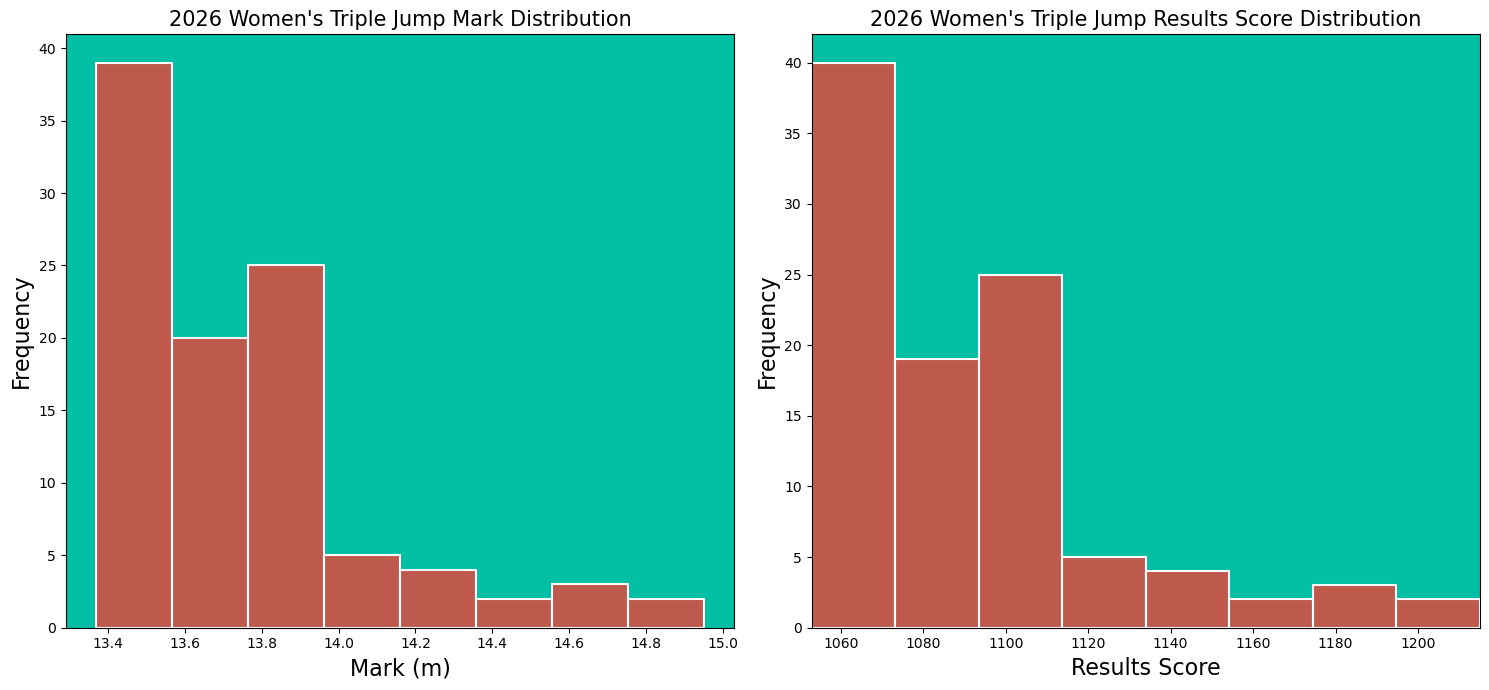

In [23]:
plot_mark_v_score("2026 Women's Triple Jump")

### 2025 Women's 1500 Metres Mark & Result Score Distributions
The histogram for Women's marks and result scores in the 1500 Metres across the 2025 season.

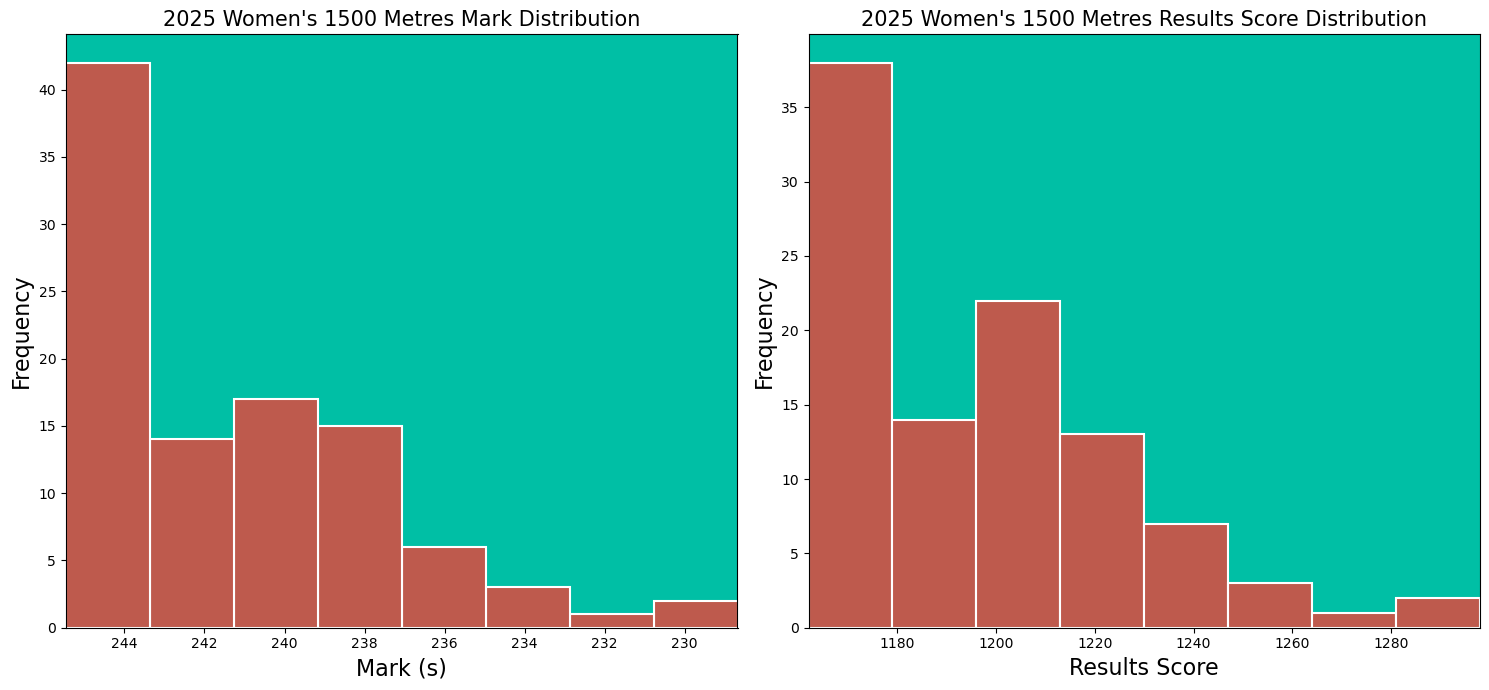

In [24]:
plot_mark_v_score("2025 Women's 1500 Metres")

## Trackflation Index
"Trackflation" refers to the recent phenomenon of times and marks getting more and more impressive and competitive at a larger scale, and a field is much faster one year than it was the previous year. Our team was interested in finding a trackflation index, in which we compare the mean of the marks across an event and year to the mean of the marks in the previous year. A trackflation index significantly greater than 1 indicates that the event has gotten much more competitive over the past two years.

In [25]:
def trackflation_visualizer(specific_event: str) -> float:
    """
    Plots a boxplot depicting yearly mark and result score distribution
    of the top 100 athletes in the given specific event. Returns the
    trackflation index (mean mark in 2026 / mean mark in 2024)
    """
    years = [2024, 2025, 2026]
    events = [pd.read_csv("event_files/" + str(year) + ' ' + specific_event + '.csv') for year in years]


    for year, event in zip(years, events):
        event['year'] = year
        event['Mark'] = event['Mark'].apply(to_float)

    combined = pd.concat(events, ignore_index=True)

    mark_means = combined.groupby('year')['Mark'].mean()
    score_means = combined.groupby('year')['Results Score'].mean()

    # Plot
    fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(15, 7))

    sns.boxplot(data=combined, x='year', y='Mark', ax=ax1, color=my_palette[1])
    ax1.plot([0, 1, 2], [mark_means[y] for y in years], color=my_palette[0], marker='o', linewidth=2, label='Mean')
    ax1.legend()
    ax1.set_title(specific_event + " Yearly Mark Distribution", fontsize=18)
    ax1.set_xlabel("Year", fontsize=16)
    ax1.set_ylabel("Mark (m)", fontsize=16)
    # ax1.set_facecolor('#9494F6')

    # reverse y axis (for running) since lower time is good result score
    if running(specific_event):
        ax1.invert_yaxis()
        ax1.set_ylabel("Mark (s)", fontsize=16)

    sns.boxplot(data=combined, x='year', y='Results Score', ax=ax2, color=my_palette[2])
    ax2.plot([0, 1, 2], [score_means[y] for y in years], color=my_palette[0], marker='o', linewidth=2, label='Mean')
    ax2.legend()
    ax2.set_title(specific_event + " Yearly Result Score Distribution", fontsize=18)
    ax2.set_xlabel("Year", fontsize=16)
    ax2.set_ylabel("Results Score", fontsize=16)
    # ax2.set_facecolor('#9494F6')
    plt.tight_layout()
    plt.show()

    trackflation_index = round(mark_means[2026] / mark_means[2024], 4)
    return trackflation_index

### Year-Over-Year Perfomance for the Women's Triple Jump
We see that the trackflation index is 0.9829.

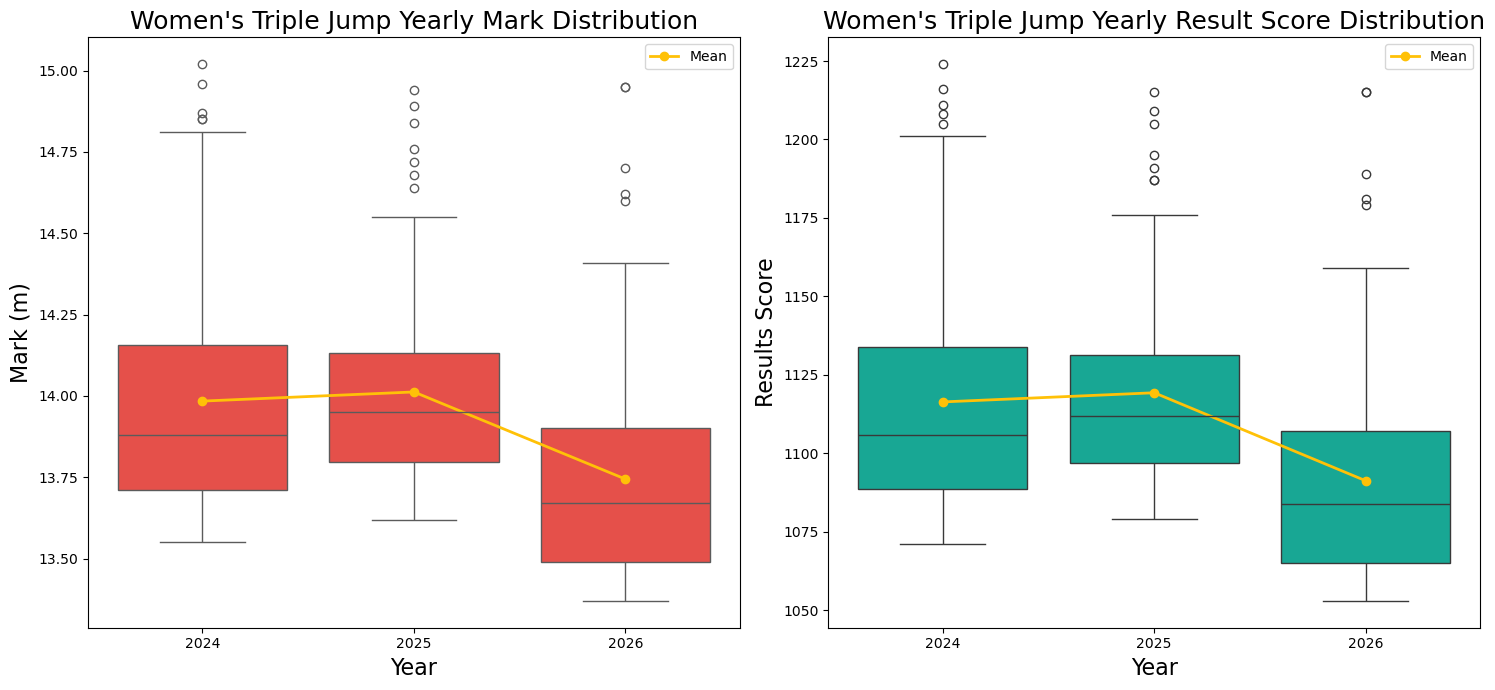

0.9829


In [26]:
print(trackflation_visualizer("Women's Triple Jump"))

### Year-Over-Year Perfomance for the Men's Shot Put
We see that the trackflation index is 0.979.

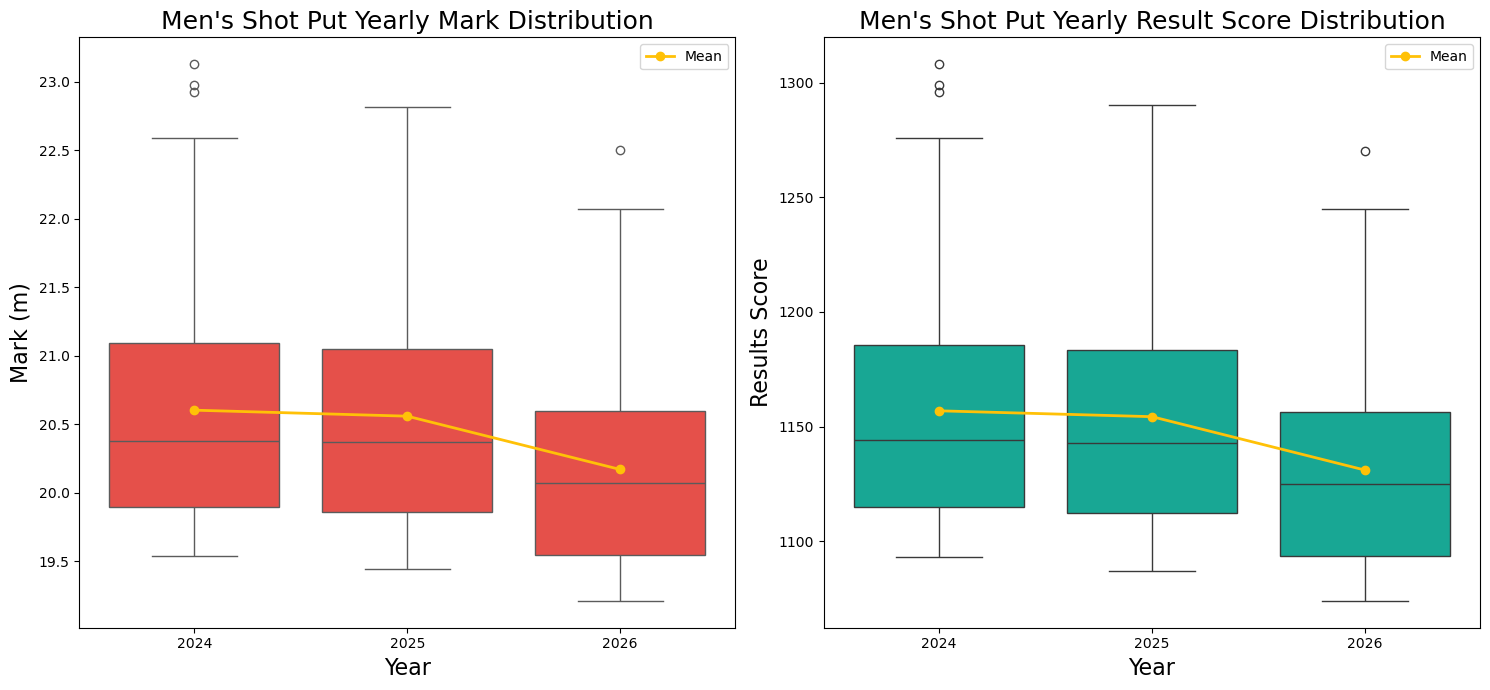

0.979


In [27]:
print(trackflation_visualizer("Men's Shot Put"))

### Year-Over-Year Perfomance for the Men's 400 Metres
We see that the trackflation index is 1.0048.

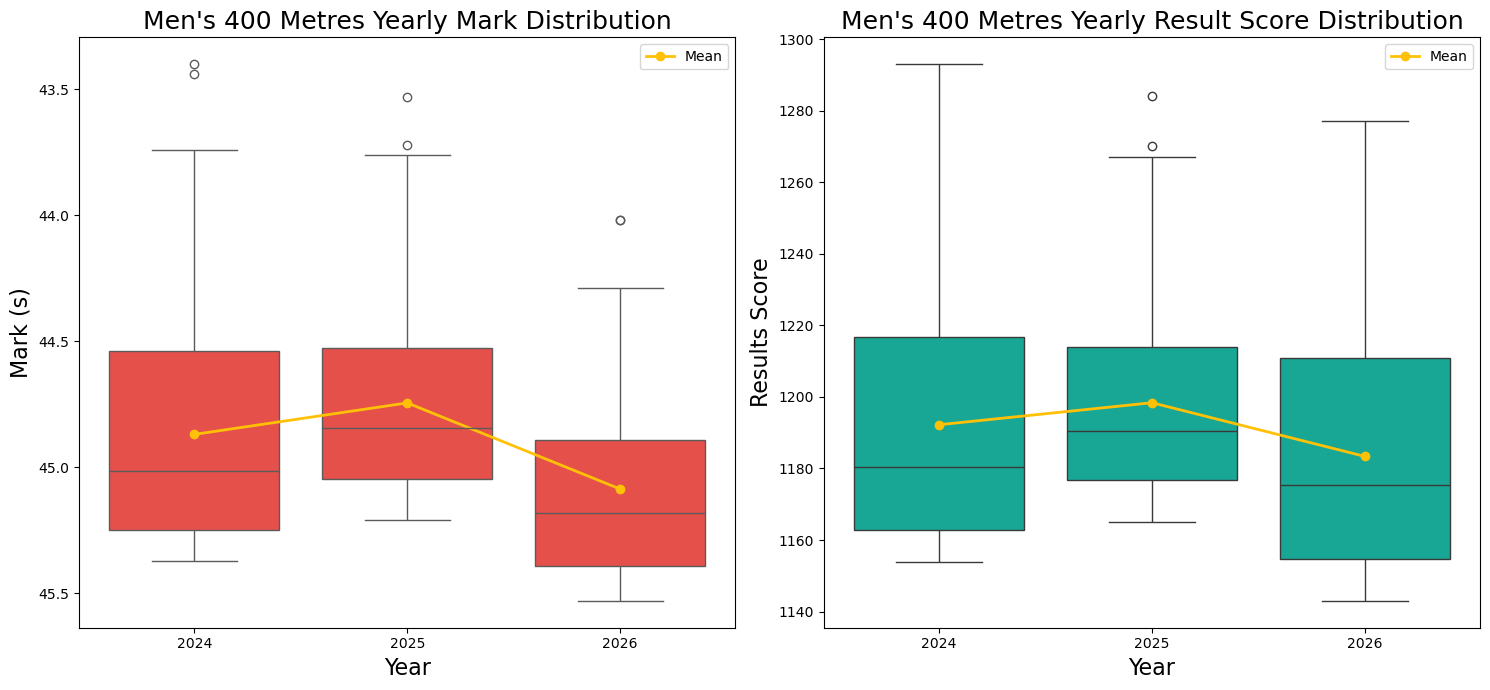

1.0048


In [28]:
print(trackflation_visualizer("Men's 400 Metres"))

## Athlete Growth
We investigated the progression of individual athletes over the course of the 2024, 2025, and 2026 seasons. This is similar to the athlete boxplot, but the violin plot allows us to see the density fo athlete performances, revealing whether an athlete is consistent or bimodal (races well at majors, underperforms otherwise). 

In [29]:
def athlete_growth(athlete_id: int, event: str) -> None:
    """
    Plots a violin plot of an athletes yearly mark performance in the given event.
    """
    # Read csv
    athlete_data = pd.read_csv("athlete_files/" + str(athlete_id) + '.csv')

    # First, add year to df
    athlete_data = add_year_df(athlete_id)
    
    # Get name
    name = athlete_data['name'][0]

    # Change 'date' column to be datetime objects    
    athlete_data['date'] = pd.to_datetime(athlete_data['date'], format='%d %b %Y')
    # Get just 5k performances
    athlete_data = athlete_data[athlete_data['discipline'] == event]    
    
    athlete_data['mark'] = athlete_data['mark'].apply(to_float)
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Plot
    sns.violinplot(data=athlete_data, x='year', y='mark', palette=my_palette, ax=ax, hue='year', legend=False, inner="box", 
               inner_kws={"box_width": 15, "linewidth": 4})
    ax.set_title(name + " Yearly Mark Distribution", fontsize=18)
    ax.set_xlabel("Year", fontsize=16)
    ax.set_ylabel("Mark (m)", fontsize=16)

    # reverse y axis (for running) since lower time is good result score
    if running(event):
        # it is a running event, we invert the axis so that a lower time is "better"
        ax.invert_yaxis()
        ax.set_ylabel("Mark (s)", fontsize=16)


    plt.tight_layout()
    plt.show()

### Grant Fisher Year-Over-Year Growth
Shows the full distribution of Grant Fisher's marks per year between 2024 and 2025.

C:\Users\rache\AppData\Local\Temp\ipykernel_19200\2393508345.py:23: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.violinplot(data=athlete_data, x='year', y='mark', palette=my_palette, ax=ax, hue='year', legend=False, inner="box",


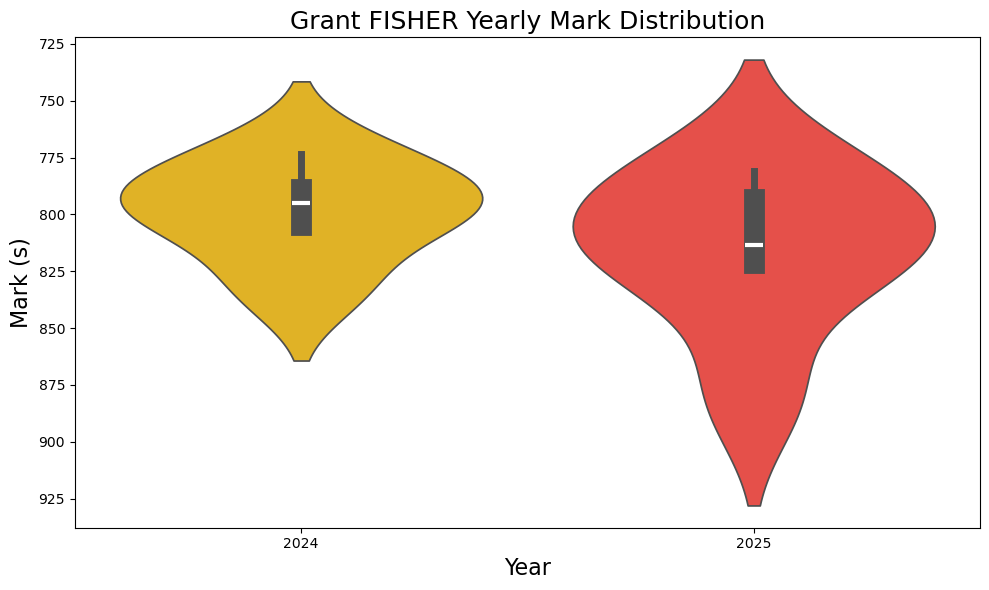

In [30]:
athlete_growth(14591210, "5000 Metres")

### Mauricio Ortega Year-Over-Year Growth
Shows the full distribution of Mauricio Ortega's marks per year between 2024, 2025, and 2026.

C:\Users\rache\AppData\Local\Temp\ipykernel_19200\2393508345.py:23: UserWarning: The palette list has more values (6) than needed (3), which may not be intended.
  sns.violinplot(data=athlete_data, x='year', y='mark', palette=my_palette, ax=ax, hue='year', legend=False, inner="box",


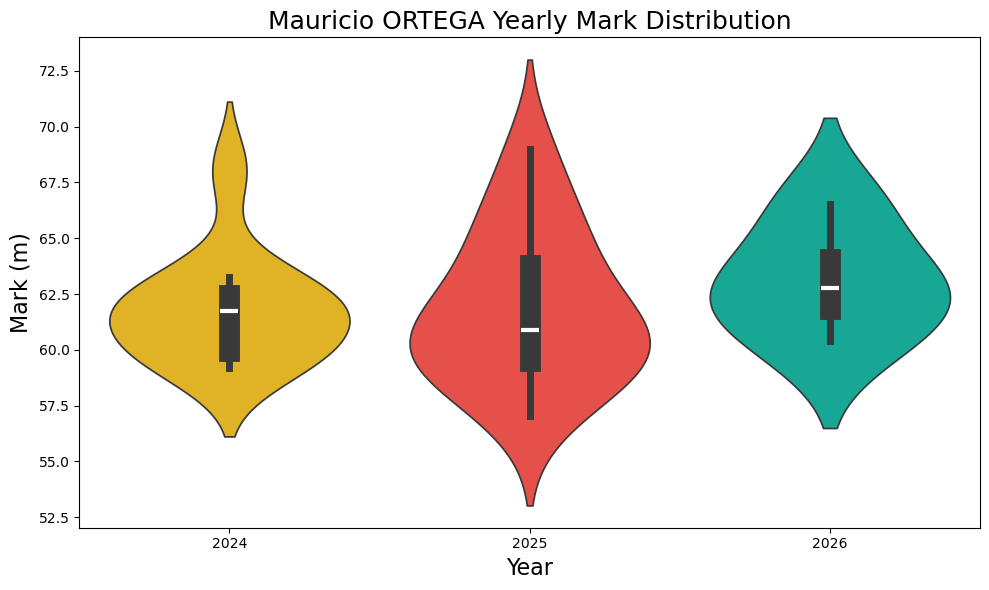

In [31]:
athlete_growth(14479637, "Discus Throw")

## Challenge Goals
### Messy Data
Our data will require scraping the internet. There exists no .csv file in which all the results we want are cleanly in. Furthermore, we are inspecting only the 48 Olympic events, which means we must filter the irrelevant events we do not want to analyze. 

Update: Our data-scraping experience was challenging but very interesting and rewarding. Darryl wrote the code to scrape the top lists, and Zubair wrote the code to scrape the individual athlete results. Rachel created the list of URLs to scrape, the labels for files, and organized the scraping process. Rachel then ran the program on her computer, which took 15 hours of computing to process all 6,344 athlete files and 120 event top lists. 

### Visualizations (UI)
We will create an interactive site that allows fans to look through data, medals, photos, and backstories of their favorite athletes. Fans can favorite athletes, compare them with other athletes, and (maybe) do sports betting. 
We will create two sets of rankings: one that ranks by pure times, and the other will use our machine learning model to rank based on who is most likely to win a championship, based on our model.

Update: We have not yet started our Fan UI project, but we plan to use some of the data visualizations we have made, as well as the analysis and linear regression performed, as part of our Fan UI. 

### Machine Learning
Make a model that is at least 50% accurate. To do so, we will take into account past performance, current performance, years in competition (tentative), background, and tactics. 

Update: Since writing the proposal, we have learned about `DecisionTreeRegressors` in class. We now plan to use a `DecisionTree` object to perform our machine learning. We still need to figure out how we will use 2025 data, and current 2026 data, to predict late 2026 outcomes. We are also still figuring out how to feed features and labels into our `DecisionTree`.


## Work Plan Evaluation
Our real work differed a bit from our Work Plan. First, we did not end up using the classes for Race, FieldMark, Athlete, etc., since the attributes that were initially stored in these objects are more easily stored in the csv’s we scraped from the Internet. It was very helpful that we decided to scrape our data before writing a lot of functional code and classes, since it is easier to work with our csv’s than our classes.
Scraping data took longer than expected. Even with help from some AI tools, the scraper file had to go to Darryl, then Rachel, then Zubair to get working. The code also took much longer to run than anticipated- the first full scrape took about 14 hours, and after some refinements and edits, the following scrapes took about 6.5 hours each. In total, we ran the scraper file about 4 times, fixing mistakes and making improvements each time we ran it.
We have not yet begun Tasks 3, 4, and 5. We assume that it will take more than a day for them to be completed, and we expect to dedicate the rest of the quarter to our ML model and UI visualization.


## Testing
We made visualizations of our data showing distributions for both Men’s and Women’s events. Our visualizations helped demonstrate that our EDA code was consistent with the data in our CSV files.

We did not use any assert statements, since we did not have beforehand the summary statistics or any samples showing what the graphs should look like. 

After loading our data, we visually confirmed that it loaded correctly by checking column names, data types, and that the values looked reasonable (times, dates, country codes, athlete IDs). The time_to_float function validated that the string parsing logic was correct before it was used on real data, as we tested each value and confirmed the output was correct. df_plot_trajectory  was first called with a single known athlete ID before being run across all athletes in the loop. This verified that the filtering, date parsing, and plotting worked correctly for one case before scaling up. If any athlete file was missing, a filename was wrong, or a data type was unexpected, it would result in an error.

## Collaboration/Other Resources
Besides course staff and team members, we used Generative AI to help us with data scraping, since no one in the team had done it before. All our data was sourced from `worldathletics.org`.